# Cycle 2a — A classical joint ranker (no neural embeddings)

**Question:** how far can retrieval go with *classical* IR signals only (BM25, TF-IDF, entities, links), and how does it compare with dense retrievers (BGE, Contriever)?

**Why ask it**
- BGE is strong on HotpotQA, but it was likely trained on HotpotQA-style data (possible contamination), and it's a black box.
- A classical ranker is fully explainable ("ranked #1 because the question names its title"), cheap, and contamination-free.

**Design**

1. **Signal lists.** Each signal produces its own ranking:
   - `bm25`: BM25 on the whole question (k1=1.2, b=0.9)
   - `tfidf`: TF-IDF cosine similarity, unigrams + bigrams
   - `title`: question entities matching the paragraph **title** (exact 1.0 / partial 0.7), weighted by entity rarity
   - `coverage`: rarity-weighted share of question entities found in the paragraph (first sentence 1.0, rest 0.6)
   - `anstype`: the paragraph contains an entity of the expected answer type (DATE for "what year"…)

   Question entities are the union of spaCy NER, a **title gazetteer** (question n-grams equal to a corpus title), quoted strings and capitalized runs. Entity rarity = IDF of the whole phrase. An entity with no exact title match is also matched **fuzzily** to titles of similar length (character-trigram Dice ≥ 0.75), which catches misspellings like "Apatim Majumdar" → *Apratim Majumdar*.
2. **Reciprocal Rank Fusion (RRF)** merges the lists using ranks only (no score normalization needed):
   $$\text{RRF}(d) = \sum_i \frac{\lambda_i}{60 + \text{rank}_i(d)}$$
   *Plain* RRF uses all $\lambda_i = 1$; *weighted* RRF tunes the $\lambda_i$.
3. **Structure**, which fusion alone can't do:
   - **Routing rule:** ≥2 named entities + a yes/no opener or comparison cue → comparison strategy; otherwise bridge strategy.
   - **Comparison:** one **reserved slot** per named entity that exactly matches a title, then fill with RRF.
   - **Bridge (two steps):** rank hop 1 with RRF, then follow **links** from the top-3 paragraphs. A link is a corpus title (or a title alias: "Nelson" for *Nelson, New Hampshire*, "MSU" for *Moscow State University*) mentioned in the paragraph, found with the title gazetteer (a classical stand-in for Wikipedia hyperlinks). A candidate reached from the hop-1 paragraph at rank *r* scores
     $$0.5^{\,r-1}\,\big(1 + \text{ov}(\text{linking sentence}) + \text{ov}(\text{candidate's first sentence})\big)$$
     where ov = the summed IDF of the question words outside the question entities that the text contains. The linked paragraphs form an extra `link` list fused into RRF.
   - **Backlinks** (paragraphs that mention the hop-1 title) were tested as an extra fallback list; see §4b for why they're off by default.

**Protocol**
- All weights were grid-searched on the **tuning questions** (pool[1500:2000]), never on the evaluation questions.
- Evaluation: the same 500 questions (pool[:500]) as every other retriever. No LLM involved.
- Latency is the full `search()` call: tokenization, all signal lists, fusion.

Code: `src/entities.py` (entities, gazetteer, links), `src/fusion.py` (rankers; `python -m src.fusion [--dense]` reproduces every row below), `src/ltr.py` (learning to rank, §8; `python -m src.ltr`).

In [3]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import bridge_hops, load_corpus, load_dev_pool
from src.entities import EntityIndex, expected_answer_types, question_entities
from src.fusion import is_comparison_like

RESULTS = PROJECT_ROOT / "results"
FIG_DIR = RESULTS / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)


def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]


pool = load_dev_pool()
pool_by_id = {e["id"]: e for e in pool}
corpus = load_corpus(pool)
pid_of = {d["title"]: i for i, d in enumerate(corpus)}
index = EntityIndex(corpus)

RUNS = {
    "TF-IDF": "cycle1_retrieval_tfidf",
    "BM25": "cycle1_retrieval_bm25",
    "Contriever": "cycle1_retrieval_contriever",
    "Contriever-MSMARCO": "cycle1_retrieval_contriever_msmarco",
    "BGE (dense)": "cycle1_retrieval_dense",
    "RRF plain": "cycle2_retrieval_rrf_plain",
    "RRF weighted": "cycle2_retrieval_rrf_weighted",
    "RRF + structure (classical)": "cycle2_retrieval_rrf_structured",
    "Contriever-MSMARCO + slots + links": "cycle2_retrieval_contriever_msmarco_links",
    "BGE + slots + links": "cycle2_retrieval_bge_links",
    "BGE + slots + links + backlinks": "cycle2_retrieval_bge_links_with_backlinks",
    "Hybrid: classical + BGE + links": "cycle2_retrieval_hybrid_bge_structured",
    "LTR: classical features": "cycle2_retrieval_ltr_classical",
    "LTR: classical + BGE": "cycle2_retrieval_ltr_hybrid_bge",
    "LTR: classical + Contriever-MSMARCO": "cycle2_retrieval_ltr_hybrid_contriever_msmarco",
}
runs = {name: pd.DataFrame(read_jsonl(RESULTS / f"{file}.jsonl")) for name, file in RUNS.items()}
print({name: len(df) for name, df in runs.items()})

{'TF-IDF': 500, 'BM25': 500, 'Contriever': 500, 'Contriever-MSMARCO': 500, 'BGE (dense)': 500, 'RRF plain': 500, 'RRF weighted': 500, 'RRF + structure (classical)': 500, 'Contriever-MSMARCO + slots + links': 500, 'BGE + slots + links': 500, 'BGE + slots + links + backlinks': 500, 'Hybrid: classical + BGE + links': 500, 'LTR: classical features': 500, 'LTR: classical + BGE': 500, 'LTR: classical + Contriever-MSMARCO': 500}


## 1. What the entity signals can and cannot see

Before building a ranker, we check the raw signals on the 500 evaluation questions:
- **Title match:** does a question entity match the gold paragraph's title?
- **Which source finds it:** spaCy NER, title gazetteer, quoted strings or capitalized runs?
- **Links:** does the gold hop-1 paragraph mention the hop-2 title (forward link), or an alias of it? Does the hop-2 paragraph mention the hop-1 title (backlink)?

In [4]:
rows, link_rows = [], []
for ex in pool[:500]:
    ents = question_entities(ex["question"], index)
    if ex["type"] == "comparison":
        roles = [("comparison", t) for t in ex["gold_titles"]]
    else:
        hops = bridge_hops(ex)
        roles = [("bridge hop 1", hops[0]), ("bridge hop 2", hops[1])] if hops else []
        if hops:
            h1, h2 = pid_of[hops[0]], pid_of[hops[1]]
            forward = h2 in index.links(h1, aliases=False)
            alias = h2 in index.links(h1)
            back = h2 in index.backlinks(h1)
            link_rows.append({"forward link (titles)": forward, "forward link (+ aliases)": alias, "backlink": back,
                              "forward or backlink": alias or back, "n_links": len(index.links(h1)), "n_backlinks": len(index.backlinks(h1))})
    for role, title in roles:
        pid = pid_of[title]
        row = {"role": role, "exact": any(index.title_match(e["text"], pid) == 1.0 for e in ents),
               "exact_or_partial": any(index.title_match(e["text"], pid) > 0 for e in ents)}
        for source in ["ner", "title", "quoted", "capitalized"]:
            row[f"via {source}"] = any(index.title_match(e["text"], pid) > 0 for e in ents if source in e["sources"])
        rows.append(row)
entity_diag = pd.DataFrame(rows).groupby("role").mean().round(2)
display(entity_diag)
links_df = pd.DataFrame(link_rows)
print(f"Gold hop 1 connected to gold hop 2 ({len(links_df)} bridge questions):")
display(links_df.drop(columns=["n_links", "n_backlinks"]).mean().round(3).to_frame("share"))
print(f"forward links per paragraph: median {links_df.n_links.median():.0f}, mean {links_df.n_links.mean():.1f} | "
      f"backlinks per paragraph: median {links_df.n_backlinks.median():.0f}, mean {links_df.n_backlinks.mean():.1f}")

,exact,exact_or_partial,via ner,via title,via quoted,via capitalized
role,,,,,,
bridge hop 1,0.65,0.73,0.52,0.66,0.04,0.41
bridge hop 2,0.15,0.19,0.13,0.15,0.02,0.12
comparison,1.00,1.00,0.77,1.00,0.02,0.87


Gold hop 1 connected to gold hop 2 (301 bridge questions):


,share
forward link (titles),0.638
forward link (+ aliases),0.648
backlink,0.266
forward or backlink,0.841


forward links per paragraph: median 2, mean 2.1 | backlinks per paragraph: median 1, mean 2.6


**Findings — signals**
- **Comparison questions name both gold titles in 100% of cases.** The title gazetteer finds all of them; spaCy NER alone finds only ~77%, since it misses or mislabels names like "Greyia" or song titles. That's why the gazetteer is the main entity source and NER is a complement.
- **Hop 1** of bridge questions is named ~65% of the time (≈73% counting partial matches).
- **Hop 2 is almost never named** (~15%): no question-side signal can find it directly.
- **Links are the way to hop 2:** in ~64% of bridge questions, the hop-1 paragraph mentions the hop-2 title. At about 2 links per paragraph, following links is very precise.
- **Title aliases add only +1 point** (64.8%). **Backlinks add much more coverage:** in 27% of cases the hop-2 paragraph mentions the hop-1 title, which raises coverage to 84%. Whether that coverage turns into top-5 hits is tested in §4b.

## 2. Main comparison (500 questions)

In [5]:
def summarize(df):
    bridge, comp = df[df.type == "bridge"], df[df.type == "comparison"]
    hop1 = hop2 = n = 0
    for _, r in bridge.iterrows():
        hops = bridge_hops(pool_by_id[r.id])
        if hops:
            top5 = r.retrieved_titles[:5]
            n += 1
            hop1 += hops[0] in top5
            hop2 += hops[1] in top5
    return {
        "both@2": df["both@2"].mean(), "both@5": df["both@5"].mean(), "both@10": df["both@10"].mean(), "both@20": df["both@20"].mean(),
        "bridge both@5": bridge["both@5"].mean(), "comparison both@5": comp["both@5"].mean(),
        "hop 1 @5": hop1 / n, "hop 2 @5": hop2 / n,
        "latency p50 ms": 1000 * df.retrieval_latency_s.median(), "latency p95 ms": 1000 * df.retrieval_latency_s.quantile(0.95),
    }


comparison = pd.DataFrame({name: summarize(df) for name, df in runs.items()}).T
display(comparison.round(3))

,both@2,both@5,both@10,both@20,bridge both@5,comparison both@5,hop 1 @5,hop 2 @5,latency p50 ms,latency p95 ms
TF-IDF,0.280,0.508,0.716,0.820,0.455,0.729,0.890,0.485,4.737,6.484
BM25,0.286,0.544,0.744,0.826,0.502,0.719,0.890,0.551,0.209,0.345
Contriever,0.220,0.470,0.592,0.684,0.401,0.760,0.827,0.462,32.765,37.811
Contriever-MSMARCO,0.344,0.602,0.702,0.776,0.520,0.948,0.920,0.558,33.135,38.033
BGE (dense),0.464,0.706,0.794,0.842,0.639,0.990,0.920,0.688,16.532,27.713
RRF plain,0.276,0.544,0.748,0.834,0.448,0.948,0.907,0.472,10.313,16.864
RRF weighted,0.284,0.576,0.780,0.842,0.490,0.938,0.907,0.528,10.109,16.158
RRF + structure (classical),0.472,0.806,0.888,0.942,0.762,0.990,0.917,0.807,10.415,16.625
Contriever-MSMARCO + slots + links,0.506,0.836,0.900,0.928,0.802,0.979,0.934,0.824,48.406,59.933
BGE + slots + links,0.540,0.842,0.916,0.932,0.804,1.000,0.934,0.860,27.448,36.065


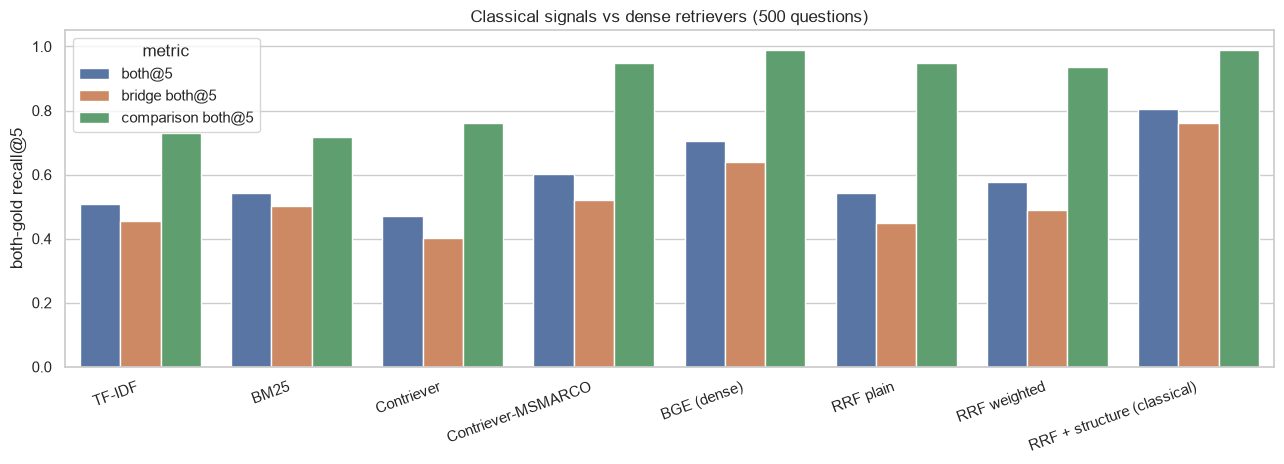

In [6]:
single_shot = ["TF-IDF", "BM25", "Contriever", "Contriever-MSMARCO", "BGE (dense)", "RRF plain", "RRF weighted", "RRF + structure (classical)"]
plot_df = comparison.loc[single_shot, ["both@5", "bridge both@5", "comparison both@5"]].reset_index(names="retriever").melt(
    id_vars="retriever", var_name="metric", value_name="value"
)
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.barplot(data=plot_df, x="retriever", y="value", hue="metric", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.set_ylabel("both-gold recall@5")
ax.set_title("Classical signals vs dense retrievers (500 questions)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "cycle2_classical_vs_dense.png", dpi=120)
plt.show()

**Findings — step by step**
- **Plain RRF ties BM25 (0.544 each), but for different reasons:** it fixes comparison questions (0.72 → 0.95), because the title list promotes the named entities, and it *hurts* bridge questions (0.50 → 0.45), because entity lists promote hop-1 look-alikes, pushing hop 2 out.
- **Tuned weights help a little (0.576):** BM25 gets the biggest weight and the answer-type list is nearly useless. Fusion can only **re-order** what the lists contain, and hop 2 is rarely near the top of any list.
- **Structure is the real gain (0.806).** Comparison reaches 0.99 through reserved slots, and hop 2 rises from 0.55 to 0.81 by following links. At 0.806 the classical ranker beats both single-shot dense retrievers (BGE 0.706, Contriever-MSMARCO 0.602).
- **Latency:** about 10 ms per question for the full classical ranker (spaCy on the question is the biggest share), against 16.5 ms for BGE and 33 ms for Contriever on CPU.

## 3. Ablation: what does each part contribute?

Remove one component from the full classical ranker and measure the drop in both-gold@5.

,both@2,both@5,bridge both@5,comparison both@5,hop 2 @5,Δ both@5
full,0.472,0.806,0.762,0.990,0.807,0.000
− links,0.350,0.588,0.493,0.990,0.512,-0.218
− BM25 list,0.306,0.606,0.517,0.979,0.724,-0.200
− TF-IDF list,0.318,0.624,0.537,0.990,0.738,-0.182
− coverage list,0.306,0.642,0.559,0.990,0.757,-0.164
− reserved slots,0.406,0.792,0.757,0.938,0.804,-0.014
− title list,0.456,0.782,0.738,0.969,0.801,-0.024
− fuzzy title matching,0.470,0.800,0.755,0.990,0.797,-0.006
− title aliases,0.478,0.808,0.765,0.990,0.811,0.002
+ gated backlinks,0.476,0.790,0.750,0.958,0.797,-0.016


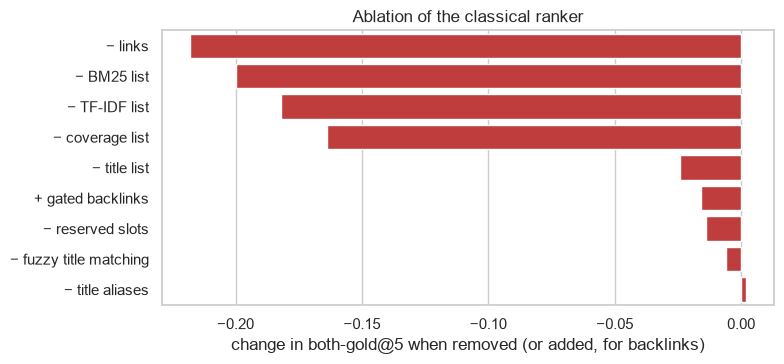

In [7]:
ABLATIONS = {
    "full": "rrf_structured",
    "− links": "rrf_structured_no_links",
    "− BM25 list": "rrf_structured_no_bm25",
    "− TF-IDF list": "rrf_structured_no_tfidf",
    "− coverage list": "rrf_structured_no_coverage",
    "− reserved slots": "rrf_structured_no_slots",
    "− title list": "rrf_structured_no_title",
    "− fuzzy title matching": "rrf_structured_no_fuzzy",
    "− title aliases": "rrf_structured_no_aliases",
    "+ gated backlinks": "rrf_structured_with_backlinks",
}
ablation = pd.DataFrame(
    {name: summarize(pd.DataFrame(read_jsonl(RESULTS / f"cycle2_retrieval_{file}.jsonl"))) for name, file in ABLATIONS.items()}
).T[["both@2", "both@5", "bridge both@5", "comparison both@5", "hop 2 @5"]]
ablation["Δ both@5"] = ablation["both@5"] - ablation.loc["full", "both@5"]
display(ablation.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
drops = ablation["Δ both@5"].drop("full").sort_values()
sns.barplot(x=drops.values, y=drops.index, color="tab:red", ax=ax)
ax.set_xlabel("change in both-gold@5 when removed (or added, for backlinks)")
ax.set_ylabel("")
ax.set_title("Ablation of the classical ranker")
plt.tight_layout()
plt.savefig(FIG_DIR / "cycle2_ablation.png", dpi=120)
plt.show()

**Findings — ablation**
- **Links matter the most (−0.22).** Without them we're back to single-shot retrieval, which can't reach hop 2.
- **The hop-1 ranking matters almost as much:** removing BM25 (−0.20), TF-IDF (−0.18) or coverage (−0.16) hurts badly. Links are followed from the top-3 paragraphs, so a worse hop-1 ranking means following the wrong links. BM25 and TF-IDF overlap, but TF-IDF's bigrams catch phrases BM25 misses, and rank-level fusion rewards agreement.
- **Slots and the title list are redundant with each other:** each costs little when removed alone (−0.01 / −0.02), because the other still promotes the named titles.
- **Fuzzy title matching helps slightly (−0.006 when removed, 3 questions),** as expected for the rare misspelled names.
- **Title aliases don't help** (+0.002 when removed): they add links for only ~1% of questions, and some of those added links are wrong.
- **Gated backlinks hurt slightly (−0.016); see §4b.**
- **The answer-type list** received weight 0 in tuning. This matches the diagnostic: the hop-2 gold paragraph contains the expected type 97% of the time, but so do 85% of distractors.

## 4. Fair comparison: the same link step on top of dense retrievers

The classical ranker is a **two-step** pipeline, while BGE and Contriever above are **single-shot**. For a fair comparison, we give the dense retrievers the *same* routing, reserved slots and link-following (tuned the same way on the tuning questions).

,single-shot,+ slots + links
Classical RRF,0.588,0.806
Contriever-MSMARCO,0.602,0.836
BGE,0.706,0.842


,both@2,both@5,both@10,both@20,bridge both@5,comparison both@5,hop 1 @5,hop 2 @5,latency p50 ms,latency p95 ms
RRF + structure (classical),0.472,0.806,0.888,0.942,0.762,0.990,0.917,0.807,10.415,16.625
Contriever-MSMARCO + slots + links,0.506,0.836,0.900,0.928,0.802,0.979,0.934,0.824,48.406,59.933
BGE + slots + links,0.540,0.842,0.916,0.932,0.804,1.000,0.934,0.860,27.448,36.065
Hybrid: classical + BGE + links,0.546,0.842,0.942,0.970,0.804,1.000,0.944,0.847,27.281,38.974


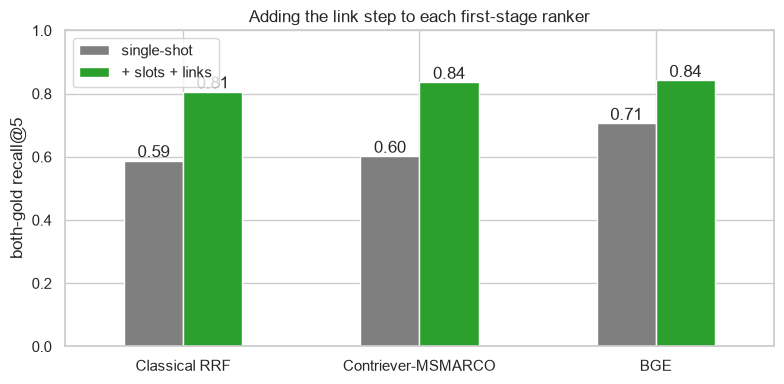

In [8]:
fair = pd.DataFrame(
    {
        "single-shot": [comparison.loc["RRF + structure (classical)", "both@5"] + ablation.loc["− links", "Δ both@5"],
                        comparison.loc["Contriever-MSMARCO", "both@5"], comparison.loc["BGE (dense)", "both@5"]],
        "+ slots + links": [comparison.loc["RRF + structure (classical)", "both@5"],
                            comparison.loc["Contriever-MSMARCO + slots + links", "both@5"], comparison.loc["BGE + slots + links", "both@5"]],
    },
    index=["Classical RRF", "Contriever-MSMARCO", "BGE"],
)
display(fair.round(3))
display(comparison.loc[["RRF + structure (classical)", "Contriever-MSMARCO + slots + links", "BGE + slots + links", "Hybrid: classical + BGE + links"]].round(3))

fig, ax = plt.subplots(figsize=(8, 4))
fair.plot.bar(ax=ax, rot=0, color=["tab:gray", "tab:green"])
ax.set_ylim(0, 1)
ax.set_ylabel("both-gold recall@5")
ax.set_title("Adding the link step to each first-stage ranker")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
plt.tight_layout()
plt.savefig(FIG_DIR / "cycle2_fair_links.png", dpi=120)
plt.show()

**Findings — fair comparison**
- **The link step helps every first stage,** by +0.14 (BGE) to +0.23 (Contriever-MSMARCO): link-following is the key multi-hop ingredient, whatever ranks hop 1.
- **With links, dense still leads, narrowly:** BGE 0.842 and Contriever-MSMARCO 0.836 vs classical 0.806. The remaining gap is mostly hop 1: questions that describe hop 1 instead of naming it.
- **The contamination gap disappears.** Single-shot, BGE leads Contriever-MSMARCO by 10 points; with links, by less than 1 point. BGE's apparent single-shot advantage on hop 2 is something links recover anyway.
- **The hybrid equals BGE + links at K=5 (0.842)** but has the best recall at K=10 / K=20 (0.942 / 0.970), which matters if a reranker or an LLM sees more candidates.
- **Cost:** the classical ranker has the lowest latency (≈10 ms, no model); dense + links costs the dense query encoding plus the link step (≈27 ms BGE, ≈48 ms Contriever).

### 4b. Backlinks: more coverage, but not more top-5 hits

Backlinks raise the share of bridge questions where hop 1 and hop 2 are connected from 65% to 84% (§1), yet they don't improve both-gold@5 reliably:

| Variant | without backlinks (tuning / evaluation) | with gated backlinks (tuning / evaluation) |
|---|---|---|
| Classical | 0.820 / 0.806 | 0.830 / 0.790 |
| BGE + links | 0.848 / 0.842 | 0.856 / 0.854 |
| Contriever-MSMARCO + links | 0.852 / 0.836 | 0.848 / 0.830 |
| Hybrid | 0.852 / 0.842 | 0.852 / 0.844 |

**Why:**
- When hop 2 is reachable *only* by a backlink (~10% of bridge questions), the backlink scoring works: it ranks hop 2 **first in the backlink list 81% of the time**.
- But adding the backlink list to every question lets its top candidate take a top-5 slot from a correct forward-linked paragraph. On the tuning questions, a backlink weight of 2 gained 10 questions and lost 18; merging backlinks into the forward list was worse still (0.806 → 0.738).
- The *gated* version adds backlinks only when the best backlink outscores the best forward link. Its tuning gains are at most 5 questions, within noise, and the evaluation changes go in both directions.

**Decision:** backlinks stay **off by default** (the simpler model), available behind a flag. The fundamental problem is that the ranker can't tell *which* direction to trust for a given question. That's a judgment call about content, which is what an LLM agent (Cycle 3) is for.

## 5. Example cases

In [9]:
bm25_df, struct_df = runs["BM25"].set_index("id"), runs["RRF + structure (classical)"].set_index("id")


def show_top5(qid, label):
    ex = pool_by_id[qid]
    print(f"[{label}] {ex['question']}\n  gold: {ex['gold_titles']}  (type: {ex['type']})")
    ents = question_entities(ex["question"], index)
    print(f"  question entities: {[(e['text'], '+'.join(e['sources'])) for e in ents]}  |  routed as: "
          f"{'comparison' if is_comparison_like(ex['question'], ents) else 'bridge'}")
    for name, df in [("BM25", bm25_df), ("classical RRF + structure", struct_df)]:
        top5 = df.loc[qid, "retrieved_titles"][:5]
        print(f"  {name:26} " + " | ".join(("✔ " if t in ex["gold_titles"] else "") + t for t in top5))
    print()


# (a) Comparison question with BM25 entity crowding, fixed by reserved slots
crowded = [qid for qid in struct_df.index if pool_by_id[qid]["type"] == "comparison" and not bm25_df.loc[qid, "both@5"] and struct_df.loc[qid, "both@5"]]
updike = [qid for qid in crowded if "Updike" in pool_by_id[qid]["question"]]
show_top5((updike or crowded)[0], "comparison: entity crowding")
print(f"Comparison questions BM25 misses but the classical ranker gets: {len(crowded)}\n")

# (b) Bridge question where hop 2 is reached through a link from hop 1
for qid in struct_df.index:
    ex = pool_by_id[qid]
    hops = bridge_hops(ex)
    if ex["type"] != "bridge" or not hops:
        continue
    hop1, hop2 = pid_of[hops[0]], pid_of[hops[1]]
    if hops[1] not in bm25_df.loc[qid, "retrieved_titles"][:5] and struct_df.loc[qid, "both@5"] and hop2 in index.links(hop1):
        show_top5(qid, "bridge: hop 2 through a link")
        print(f"  link: '{hops[0]}' sentence {index.links(hop1)[hop2]}: \"{corpus[hop1]['sentences'][index.links(hop1)[hop2]]}\"\n")
        break

[comparison: entity crowding] Did John Updike and Tom Clancy both publish more than 15 bestselling novels?
  gold: ['John Updike', 'Tom Clancy']  (type: comparison)
  question entities: [('john updike', 'ner+title+capitalized'), ('tom clancy', 'ner+title+capitalized')]  |  routed as: comparison
  BM25                       Tom Clancy's Net Force Explorers: Gameprey | Tom Clancy's Net Force Explorers: Deathworld | Tom Clancy's Net Force Explorers: Cold Case | Tom Clancy's Net Force Explorers: Duel Identity | Tom Clancy's Net Force Explorers: Safe House
  classical RRF + structure  ✔ John Updike | ✔ Tom Clancy | Tom Clancy's Net Force Explorers: Deathworld | Tom Clancy's Net Force Explorers: Gameprey | Tom Clancy's Net Force Explorers: Safe House

Comparison questions BM25 misses but the classical ranker gets: 26

[bridge: hop 2 through a link] In what year was the university where Sergei Aleksandrovich Tokarev was a professor founded?
  gold: ['Moscow State University', 'Sergei Aleksand

## 6. Where the classical ranker still fails (bridge questions)

Each bridge miss (both gold paragraphs not in the top 5) is put in the first category that applies:
1. **hop 1 missed**: the hop-1 paragraph isn't in the top 5, so there's nothing to follow.
2. **link outranked**: the forward link exists, but other candidates beat the linked paragraph.
3. **only a backlink**: hop 1 doesn't mention hop 2, but hop 2 mentions hop 1 (reachable only by a backlink).
4. **no link in either direction**: the connection is a fact or a description, not a named mention.

In [10]:
fail_rows = []
for qid, r in struct_df.iterrows():
    ex = pool_by_id[qid]
    hops = bridge_hops(ex)
    if ex["type"] != "bridge" or not hops or r["both@5"]:
        continue
    top5 = r.retrieved_titles[:5]
    h1, h2 = pid_of[hops[0]], pid_of[hops[1]]
    if hops[0] not in top5:
        category = "hop 1 missed"
    elif h2 in index.links(h1):
        category = "link outranked"
    elif h2 in index.backlinks(h1):
        category = "only a backlink hop 2 → hop 1"
    else:
        category = "no link in either direction"
    fail_rows.append({"id": qid, "category": category, "question": ex["question"], "gold": ex["gold_titles"]})
fails = pd.DataFrame(fail_rows)
n_bridge = sum(1 for qid in struct_df.index if pool_by_id[qid]["type"] == "bridge" and bridge_hops(pool_by_id[qid]))
print(f"bridge misses: {len(fails)} of {n_bridge} bridge questions with hop labels")
display(fails.category.value_counts().to_frame("count"))
for category in fails.category.unique():
    display(fails[fails.category == category].head(2)[["question", "gold"]].assign(category=category))

bridge misses: 73 of 301 bridge questions with hop labels


,count
category,
no link in either direction,27
hop 1 missed,25
only a backlink hop 2 → hop 1,16
link outranked,5


,question,gold,category
0,The Prussian General Carl von Clausewitz is associated with what type of realism?,"[Carl von Clausewitz, Classical realism (international relations)]",only a backlink hop 2 → hop 1
3,Who is writing a book about the Koch family who control the second-largest privately owned company in the United Sta...,"[Dark Money (book), Koch family]",only a backlink hop 2 → hop 1


,question,gold,category
1,what language did the ethnic group which Torstein Ellingsen was its drumer speaks,"[Norwegians, Torstein Ellingsen]",no link in either direction
2,"Which head coach has led their team for a longer period of time, Tim Cluess or Steve Prohm?","[2015–16 Iona Gaels men's basketball team, 2015–16 Iowa State Cyclones men's basketball team]",no link in either direction


,question,gold,category
4,"In what city did the ""Prince of tenors"" star in a film based on an opera by Giacomo Puccini?","[Franco Corelli, Tosca (1956 film)]",hop 1 missed
7,What is the ratio of flow velocity past a boundary to the local speed of sound for a Saab JAS 39 Gripen?,"[Mach number, Saab JAS 39 Gripen]",hop 1 missed


,question,gold,category
14,"Which king of Northumbria did The ""Historia"" gives the abbot central place in his election as king","[Eadred Lulisc, Guthred]",link outranked
18,"Where is the concert venue which hosted the first US performance of ""Libuše"" located?","[Carnegie Hall, Libuše (opera)]",link outranked


**Findings — failures** (73 of 301 bridge questions)
- **No link in either direction (27):** the connection is a description or a fact, not a named mention. "Norwegian" (too common a word to count as a link) vs *Norwegians*; a head coach's name vs *2015–16 Iona Gaels men's basketball team*. Only reading comprehension helps here, i.e. an LLM writing the next query (Cycle 3).
- **Hop 1 missed (25):** the question describes hop 1 instead of naming it ("the 'Prince of tenors'" = *Franco Corelli*; "the ratio of flow velocity … to the speed of sound" = *Mach number*), so nothing points to it.
- **Only a backlink (16):** hop 2 mentions hop 1 but not vice versa (Clausewitz ← *Classical realism*, Koch family ← *Dark Money*). Backlinks could fix these in principle, but they cost as many other questions as they gain (§4b).
- **Link outranked (5):** down from 12 with the first link scoring (raw word-overlap count). Adding the candidate's first sentence and IDF weighting fixed most of these.

## 7. Routing rule check

The routing rule sends questions to the comparison strategy (slots) or the bridge strategy (links). How does it agree with HotpotQA's own type labels?

In [11]:
routing = pd.crosstab(
    pd.Series([pool_by_id[qid]["type"] for qid in struct_df.index], name="HotpotQA type"),
    pd.Series(["comparison" if is_comparison_like(pool_by_id[qid]["question"], question_entities(pool_by_id[qid]["question"], index)) else "bridge"
               for qid in struct_df.index], name="routed as"),
)
display(routing)
print(f"agreement: {(routing.values.trace() / routing.values.sum()):.1%}")

routed as,bridge,comparison
HotpotQA type,,
bridge,361,43
comparison,8,88


agreement: 89.8%


The ~10% disagreement is mostly harmless. Many HotpotQA "bridge" questions are comparison-shaped for retrieval, e.g. *"Who was born first, Umar Israilov or Ramzan Kadyrov?"* Both gold paragraphs are named in the question, so reserved slots are the right strategy regardless of the label.

## 8. Learning to rank: LambdaMART instead of hand-tuned RRF

**Why.** RRF + structure has about 15 hand-set knobs: list weights per question type, hop-1 depth, link decay, backlink margin. It also has hard if-then rules (routing, reserved slots, the backlink gate). RRF only sees **ranks**, so it can't tell a confident BM25 score of 40 from a marginal 12. It also can't express interactions like "trust backlinks only when the forward links look weak", which is why §4b had to gate backlinks by hand.

**How learning to rank (LTR) replaces them:**
1. **Candidates.** Per question, take the union of the top 50 of every list (BM25, TF-IDF, title, coverage, answer type, [dense]), the structured-RRF ranking, the reserved slots, and the forward and backward link candidates. That's about 95 paragraphs, and both gold paragraphs are inside for about 99% of questions. That's the ceiling for any reranker.
2. **Features.** Every (question, paragraph) pair becomes 30 numbers in 7 groups (table below): raw scores and ranks per signal, entity and link evidence (for example, "linked from the hop-1 paragraph ranked 1st, by 2 hop-1 paragraphs"), the RRF ranks themselves, and question and paragraph descriptors. A missing value (the paragraph isn't in that list) stays missing; trees handle that natively.
3. **LambdaMART** (LightGBM `LGBMRanker`, objective `lambdarank`) is an ensemble of small decision trees trained on **pairs**. Within a question, for every (gold, non-gold) pair, it pushes the gold paragraph up. Each pair is weighted by how much swapping the two would change NDCG@5, so mistakes at the top of the ranking count most.

**Protocol**
- Train on pool[500:1500]: 1,000 questions, never used before.
- Early stopping and a 6-point grid (tree size × minimum leaf size) on pool[1500:2000], the same questions the RRF weights were tuned on.
- Test on the same 500 evaluation questions.
- Labels are 1 for the two gold paragraphs and 0 otherwise.
- This is classical ML on about 95k rows: training takes about 1 s on the laptop, and there's no LLM or neural training.

Three variants: classical features only, classical + BGE scores, and classical + Contriever-MSMARCO scores.

In [12]:
from scipy.stats import binomtest

from src.ltr import FEATURE_GROUPS

display(pd.DataFrame({"features": {g: ", ".join(names) for g, names in FEATURE_GROUPS.items()}}))
ltr_summary = pd.read_csv(RESULTS / "summary_cycle2_ltr.csv").set_index("retriever")
display(ltr_summary.round(3))

LTR_VIEW = ["RRF + structure (classical)", "LTR: classical features", "BGE + slots + links", "Hybrid: classical + BGE + links",
            "Contriever-MSMARCO + slots + links", "LTR: classical + BGE", "LTR: classical + Contriever-MSMARCO"]
display(comparison.loc[LTR_VIEW].round(3))

,features
question,"is_comparison, n_entities, n_named, question_len, has_anstype"
lexical,"bm25, bm25_rel, bm25_rank, tfidf, tfidf_rel, tfidf_rank"
dense,"dense, dense_gap, dense_rank"
entity,"title_score, title_rank, is_slot, coverage, coverage_rank, anstype"
rrf,"bridge_rrf_rank, comparison_rrf_rank, structured_rank"
link,"fwd_score, fwd_rank, fwd_parent_rank, fwd_parent_count, back_score, back_rank, back_parent_rank"
paragraph,"first_sentence_overlap, title_in_question, paragraph_len"


,num_leaves,min_child_samples,learning_rate,n_trees,candidate_recall,val both@5,both@2,both@5,both@10,both@20,latency p50 ms
retriever,,,,,,,,,,,
ltr_classical,7,50,0.05,268,0.986,0.880,0.710,0.898,0.936,0.962,16.339
ltr_hybrid_bge,31,50,0.05,74,0.994,0.916,0.756,0.920,0.964,0.976,35.477
ltr_hybrid_contriever_msmarco,15,50,0.05,245,0.992,0.906,0.744,0.924,0.962,0.976,58.679


,both@2,both@5,both@10,both@20,bridge both@5,comparison both@5,hop 1 @5,hop 2 @5,latency p50 ms,latency p95 ms
RRF + structure (classical),0.472,0.806,0.888,0.942,0.762,0.990,0.917,0.807,10.415,16.625
LTR: classical features,0.710,0.898,0.936,0.962,0.874,1.000,0.960,0.907,16.262,27.769
BGE + slots + links,0.540,0.842,0.916,0.932,0.804,1.000,0.934,0.860,27.448,36.065
Hybrid: classical + BGE + links,0.546,0.842,0.942,0.970,0.804,1.000,0.944,0.847,27.281,38.974
Contriever-MSMARCO + slots + links,0.506,0.836,0.900,0.928,0.802,0.979,0.934,0.824,48.406,59.933
LTR: classical + BGE,0.756,0.920,0.964,0.976,0.901,1.000,0.973,0.920,35.454,51.106
LTR: classical + Contriever-MSMARCO,0.744,0.924,0.962,0.976,0.906,1.000,0.973,0.934,58.678,79.908


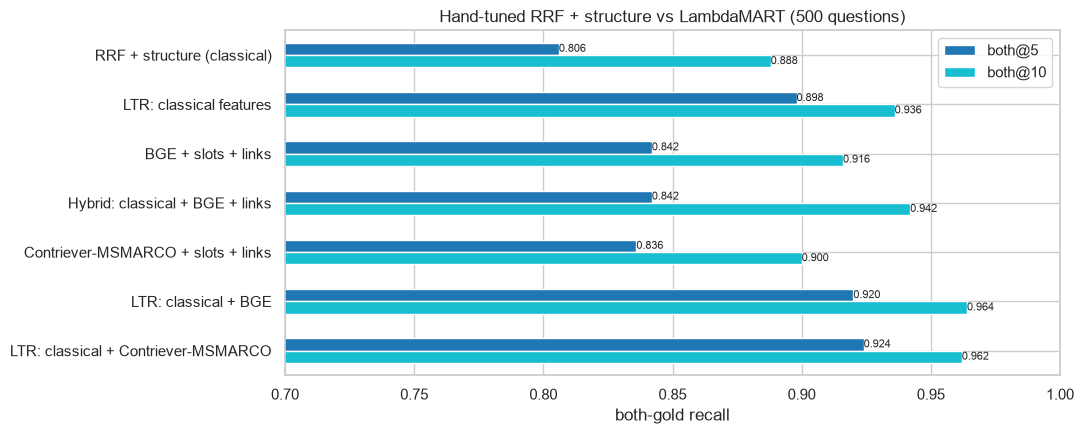

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.5))
plot_df = comparison.loc[LTR_VIEW, ["both@5", "both@10"]]
plot_df.plot.barh(ax=ax, color=["tab:blue", "tab:cyan"])
ax.invert_yaxis()
ax.set_xlim(0.7, 1.0)
ax.set_xlabel("both-gold recall")
ax.set_title("Hand-tuned RRF + structure vs LambdaMART (500 questions)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "cycle2_ltr.png", dpi=120)
plt.show()

### 8a. Is the gain real? Wins and losses per question, and which failures it fixes

In [14]:
ltr_df = runs["LTR: classical features"].set_index("id")
wins = ltr_df.index[(ltr_df["both@5"] == 1) & (struct_df["both@5"] == 0)]
losses = ltr_df.index[(ltr_df["both@5"] == 0) & (struct_df["both@5"] == 1)]
print(f"LTR (classical) vs RRF + structure: {len(wins)} questions won, {len(losses)} lost; "
      f"sign test p = {binomtest(len(wins), len(wins) + len(losses)).pvalue:.1e}")
fails["fixed by LTR"] = fails["id"].map(lambda q: bool(ltr_df.loc[q, "both@5"]))
display(fails.groupby("category")["fixed by LTR"].agg(["count", "sum", "mean"]).rename(
    columns={"count": "RRF misses", "sum": "fixed by LTR", "mean": "share fixed"}).round(2))

for qid in [q for q in wins if pool_by_id[q]["type"] == "bridge"][:3]:
    ex = pool_by_id[qid]
    print(f"\n{ex['question']}\n  gold: {ex['gold_titles']}")
    for name, df in [("RRF + structure", struct_df), ("LTR", ltr_df)]:
        print(f"  {name:16} " + " | ".join(("✔ " if t in ex["gold_titles"] else "") + t for t in df.loc[qid, "retrieved_titles"][:5]))

LTR (classical) vs RRF + structure: 48 questions won, 2 lost; sign test p = 2.3e-12


,RRF misses,fixed by LTR,share fixed
category,,,
hop 1 missed,25,14,0.56
link outranked,5,4,0.80
no link in either direction,27,8,0.30
only a backlink hop 2 → hop 1,16,11,0.69



Black Book starred the actress and writer of what heritage?
  gold: ['Black Book (film)', 'Halina Reijn']
  RRF + structure  Black Book (novel) | Black Book (non-standard disc format) | Black Book (World War II) | ✔ Black Book (film) | Le Livre noir du capitalisme
  LTR              ✔ Halina Reijn | ✔ Black Book (film) | Black Book (non-standard disc format) | Black Book (World War II) | Le Livre noir du capitalisme

The Prussian General Carl von Clausewitz is associated with what type of realism?
  gold: ['Carl von Clausewitz', 'Classical realism (international relations)']
  RRF + structure  ✔ Carl von Clausewitz | On War | The 88 | Absolute war | Prussian P 2
  LTR              ✔ Carl von Clausewitz | On War | ✔ Classical realism (international relations) | Battle of Wavre | Absolute war

what language did the ethnic group which Torstein Ellingsen was its drumer  speaks 
  gold: ['Norwegians', 'Torstein Ellingsen']
  RRF + structure  ✔ Torstein Ellingsen | Hamlet (crater) | Hamlet 

### 8b. What does the model rely on? Importance, ablation, learning curve

- **Gain importance** is the share of the total loss reduction contributed by splits on each feature.
- **Ablation** retrains without one feature group; this is what the model actually *needs*.
- **Learning curve** retrains on fewer training questions.

retriever,ltr_classical,ltr_hybrid_bge,ltr_hybrid_contriever_msmarco
group,,,
dense,NaN,0.066,0.066
entity,0.047,0.019,0.030
lexical,0.103,0.019,0.033
link,0.075,0.076,0.084
paragraph,0.024,0.013,0.016
question,0.002,0.005,0.004
rrf,0.749,0.802,0.766


,feature,group,gain
19,structured_rank,rrf,0.679
17,bridge_rrf_rank,rrf,0.066
6,bm25_rel,lexical,0.048
7,bm25_rank,lexical,0.021
21,fwd_rank,link,0.021
15,coverage_rank,entity,0.016
20,fwd_score,link,0.015
22,fwd_parent_rank,link,0.014


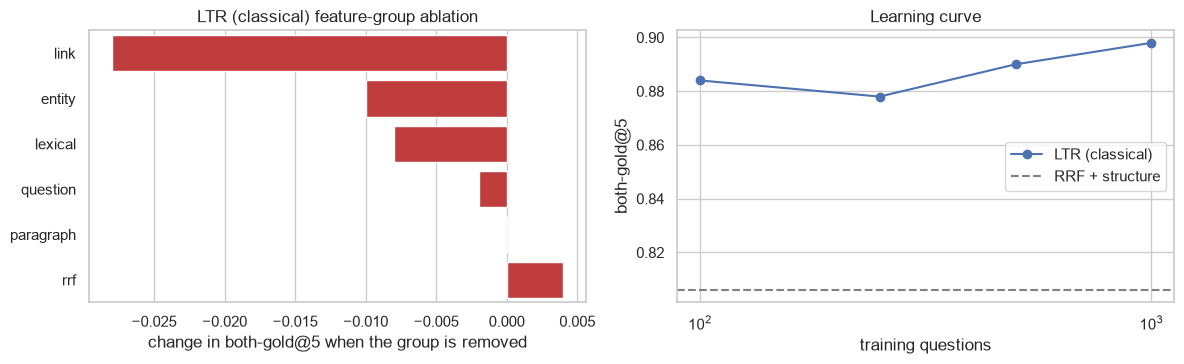

In [15]:
importance = pd.read_csv(RESULTS / "summary_cycle2_ltr_importance.csv")
display(importance.pivot_table(index="group", columns="retriever", values="gain", aggfunc="sum").round(3))
display(importance[importance.retriever == "ltr_classical"].nlargest(8, "gain")[["feature", "group", "gain"]].round(3))
ltr_ablation = pd.read_csv(RESULTS / "summary_cycle2_ltr_ablation.csv").set_index("removed")
curve = pd.read_csv(RESULTS / "summary_cycle2_ltr_learning_curve.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.barplot(x=ltr_ablation["delta"].sort_values().values, y=ltr_ablation["delta"].sort_values().index, color="tab:red", ax=axes[0])
axes[0].set_xlabel("change in both-gold@5 when the group is removed")
axes[0].set_ylabel("")
axes[0].set_title("LTR (classical) feature-group ablation")
axes[1].plot(curve["train questions"], curve["both@5"], marker="o", label="LTR (classical)")
axes[1].axhline(comparison.loc["RRF + structure (classical)", "both@5"], color="gray", ls="--", label="RRF + structure")
axes[1].set_xscale("log")
axes[1].set_xlabel("training questions")
axes[1].set_ylabel("both-gold@5")
axes[1].set_title("Learning curve")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "cycle2_ltr_ablation.png", dpi=120)
plt.show()

### 8c. Leakage checks

A 9-point jump from a re-weighting deserves suspicion. Three checks:
1. **"Gold-looking" paragraphs:** does the model favor paragraphs that are gold for *some other* question in the pool (20% of the corpus)?
2. **Paragraph-only prior:** how far does a model that sees only paragraph length and title-question overlap get?
3. **Tuning vs evaluation:** is the evaluation score in line with the validation score?

In [16]:
import pickle

from src.ltr import LTR_CACHE, both_at, train

gold_anywhere = {t for ex in pool for t in ex["gold_titles"]}


def other_gold_share(df):
    wrong = [t for _, r in df.iterrows() for t in r.retrieved_titles[:5] if t not in r.gold_titles]
    return sum(t in gold_anywhere for t in wrong) / len(wrong)


print(f"non-gold top-5 paragraphs that are gold for another question: "
      f"LTR {other_gold_share(runs['LTR: classical features']):.3f} vs RRF + structure {other_gold_share(runs['RRF + structure (classical)']):.3f}"
      f" (corpus share {len(gold_anywhere) / len(corpus):.3f})")
cached = {s: pickle.load(open(LTR_CACHE / f"ltr_classical_{s}.pkl", "rb")) for s in ("train", "val", "test")}
names = cached["train"]["names"]
groups = {s: c["groups"] for s, c in cached.items()}
for cols in (["paragraph_len"], ["paragraph_len", "title_in_question"]):
    idx = [names.index(c) for c in cols]
    print(f"model on {cols} only: test both@5 {both_at(train(groups['train'], groups['val'], idx), groups['test'], idx, corpus):.3f}")
print(f"LTR classical: validation both@5 {ltr_summary.loc['ltr_classical', 'val both@5']:.3f}, evaluation {ltr_summary.loc['ltr_classical', 'both@5']:.3f}")

non-gold top-5 paragraphs that are gold for another question: LTR 0.101 vs RRF + structure 0.137 (corpus share 0.203)
model on ['paragraph_len'] only: test both@5 0.130
model on ['paragraph_len', 'title_in_question'] only: test both@5 0.386
LTR classical: validation both@5 0.880, evaluation 0.898


**Findings — learning to rank**

**Quality**
- **LambdaMART beats every hand-built ranker.** With classical features only, it gets **0.898** vs 0.806 for RRF + structure (+9 points). It even beats the best hand-tuned dense systems (BGE + links and the hybrid, both 0.842) without any neural model.
- **The gain is all on bridge questions:** 0.76 → 0.87, with hop 2 going 0.81 → 0.91. Comparison questions were already at 0.99.
- **It's not noise:** 48 questions won vs 2 lost (sign test p ≈ 1e-12).
- **The top 2 improves the most:** both-gold@2 goes 0.47 → 0.71. That matters if the LLM is given only a couple of paragraphs.
- **With dense scores as extra features:** 0.920 (BGE) and **0.924 (Contriever-MSMARCO)**, with both-gold@10 about 0.96 and @20 about 0.98. The clean retriever matches the possibly-contaminated one.

**Why it works**
- **It uses score confidence and interactions that RRF can't.** In the examples, it demotes same-name look-alikes (*Black Book (novel)*, *(disc format)*… when the question is about the film) and promotes a candidate reached by a link whose first sentence matches the question.
- **It fixes failures that §4b couldn't.** It fixes 11 of the 16 "only a backlink" misses (69%): the backlink features that hurt as an always-on RRF list become useful when a model decides *when* to trust them.
- **It fixes other failure types too:** 4 of 5 "link outranked", 14 of 25 "hop 1 missed" (a better hop-1 ranking from combining scores), and even 8 of 27 "no link in either direction". For example, *Norwegians* has no link from *Torstein Ellingsen*, but its first sentence matches "ethnic group … speaks".

**What it relies on**
- **Importance ≠ necessity.** The structured-RRF rank takes about 70% of the gain importance, but removing *all* RRF features costs nothing (+0.004). The trees rebuild the same information from the raw scores and ranks. Gain importance shows what the model happened to split on, not what it needs.
- **Links are the one group it can't do without (−0.028 when removed).** The other groups overlap and substitute for each other (−0.01 or less each).
- **It barely needs data.** Trained on only 100 questions, it already gets 0.884. The gain comes from the model's flexibility, not from a big training set. All 6 grid points land within 0.876–0.880 on validation, so it's not sensitive to hyperparameters either.

**Leakage and cost**
- **No sign of leakage.** The model picks *fewer* "gold for another question" paragraphs than RRF, so it doesn't favor gold-looking paragraphs. Validation (0.880) and evaluation (0.898) are consistent.
- **One mild corpus artifact:** gold paragraphs are a bit shorter than HotpotQA's TF-IDF-chosen distractors. Length alone puts both golds in the top 5 for about 13% of questions (random ordering: 0.2%), but removing the paragraph features doesn't change the score.
- **Cost:** 16 ms per question for the classical LTR, against 10 ms for RRF + structure. Almost all of it is Python feature extraction for about 95 candidates; the model itself takes 0.6 ms. The dense variants cost 35 ms (BGE) and 59 ms (Contriever).

**Caveat — supervision.** LTR learns from gold labels on 1,000 HotpotQA questions from the same distribution. That's the *same kind* of in-domain supervision we flagged for BGE, just much smaller, fully visible, and on disjoint questions. The learning curve (0.884 from 100 questions) shows it doesn't need much.

## 9. Summary and caveats

| Finding | Evidence |
|---|---|
| Merging classical lists alone (RRF) doesn't beat BM25 | plain 0.544, tuned 0.576 vs BM25 0.544 |
| Entity/title signals solve comparison questions | 0.99 with reserved slots (BM25 0.72) |
| Following links is the key to hop 2 | classical hop 2 0.55 → 0.81; ablation −0.22 |
| Link scoring matters: overlap of the linking sentence *and* the candidate's first sentence | "link outranked" failures 12 → 5; classical 0.792 → 0.806 |
| A fully classical ranker beats single-shot dense retrievers | 0.806 vs BGE 0.706, Contriever-MSMARCO 0.602, at ≈10 ms |
| …but dense + the same link step is best, narrowly | BGE + links 0.842, Contriever-MSMARCO + links 0.836 |
| The contamination advantage of BGE disappears with links | gap 10 pts single-shot → <1 pt with links |
| More link coverage ≠ more top-5 hits | backlinks: coverage 65% → 84%, both-gold@5 unchanged or worse |
| A learned combiner beats hand-tuned RRF + rules by a wide margin | LambdaMART: classical 0.806 → 0.898 (48 wins, 2 losses); @2 0.47 → 0.71 |
| With a learned combiner, the clean dense retriever matches BGE | LTR + Contriever-MSMARCO 0.924 vs LTR + BGE 0.920 |

**Caveats**
- **The closed corpus flatters the gazetteer links.** The title gazetteer holds only our 19,260 titles. Against full Wikipedia (≈5M titles), scanning text for titles would find many spurious links; in an open setting one would use real hyperlinks instead, as graph-based multi-hop retrievers do.
- **The weights were tuned on only 500 questions** with a coarse grid; the small tuning-to-evaluation drop (0.820 → 0.806) suggests mild overfitting at most. Differences under ~2 points (10 questions) are within noise.
- **Retrieval recall is not answer quality.** The next step is to measure whether better top-5 evidence becomes better answers with the same LLM.

**What it means for the next cycles**
- The link step is essentially a fixed, rule-based **"read hop 1, then search for what it mentions."** That's exactly what the single agent (Cycle 3) will do with an LLM deciding the next query. We now have a strong non-agent baseline for it.
- For Cycle 2 RAG runs, the candidates are the **LambdaMART rankers**: classical features only (0.898, no neural model, 16 ms) or + Contriever-MSMARCO (0.924, contamination-free).

In [17]:
summary_cols = ["both@2", "both@5", "both@10", "both@20", "bridge both@5", "comparison both@5", "hop 1 @5", "hop 2 @5", "latency p50 ms", "latency p95 ms"]
comparison[summary_cols].to_csv(RESULTS / "summary_cycle2_retrieval.csv")
ablation.to_csv(RESULTS / "summary_cycle2_ablation.csv")
print("saved")

saved
